# Growth Rate & Phase Speed Analysis

## Import package

In [52]:
import h5py
import numpy as np

from typing import cast
from pathlib import Path

from matplotlib import pyplot as plt

style_path = Path("scientific.mplstyle")
if not style_path.is_file():
    style_path = Path("Analysis") / style_path
plt.style.use(style_path)

## Load data

In [53]:
# path setup
data_path: Path = Path("/work/b11209013/Kuang-python/v0.1.0/two-way")

# pre-allocate dictionary
dominant_mode: dict[str, np.ndarray] = {}
nondim_k     : dict[str, np.ndarray] = {}
growth_rate  : dict[str, np.ndarray] = {}
phase_speed  : dict[str, np.ndarray] = {}
eigenvalue   : dict[str, np.ndarray] = {}

# Load NoRad experiment
with h5py.File(data_path / "2026-10-23-22-49-17-016775038-2530645" / "EigenAnalysis.h5", "r") as f:
    
    # Dominant mode
    dominant_mode["NoRad"] = cast(h5py.Dataset, f["DominantMode"])[:]
    # non-dimensional wavenumber
    nondim_k["NoRad"] = cast(h5py.Dataset, f["nondim_k"])[:]
    # Eigenvalue
    eigenvalue["NoRad"] = cast(h5py.Dataset, f["Eigenvalues"])[:]

    # Growth Rate
    growth_rate["NoRad"] = cast(h5py.Dataset, f["GrowthRates"])[:]
    # Phase Speed
    phase_speed["NoRad"] = cast(h5py.Dataset, f["PhaseSpeeds"])[:]

# Load Rad experiment
with h5py.File(data_path / "2026-10-23-21-40-38-675182826-3061099" / "EigenAnalysis.h5", "r") as f:
    
    # Dominant mode
    dominant_mode["Rad"] = cast(h5py.Dataset, f["DominantMode"])[:]
    # non-dimensional wavenumber
    nondim_k["Rad"] = cast(h5py.Dataset, f["nondim_k"])[:]
    # Growth Rate
    growth_rate["Rad"] = cast(h5py.Dataset, f["GrowthRates"])[:]
    # Eigenvalue
    eigenvalue["Rad"] = cast(h5py.Dataset, f["Eigenvalues"])[:]
    # Phase Speed
    phase_speed["Rad"] = cast(h5py.Dataset, f["PhaseSpeeds"])[:]

# select growth rate and phase speed corresponding to dominant mode
dominant_growth_rate: dict[str, np.ndarray] = {
    key: growth_rate[key][dominant_mode[key][i], :]
    for key in growth_rate.keys()
    for i in range(dominant_mode[key].shape[0])
}
# Select the dominant mode separately at each wavenumber.
dominant_phase_speed: dict[str, np.ndarray] = {
    key: phase_speed[key][dominant_mode[key], np.arange(nondim_k[key].size)]
    for key in phase_speed.keys()
}

## Visualizing contrast of growth rate and phase speed between experiments

### Figure visualization

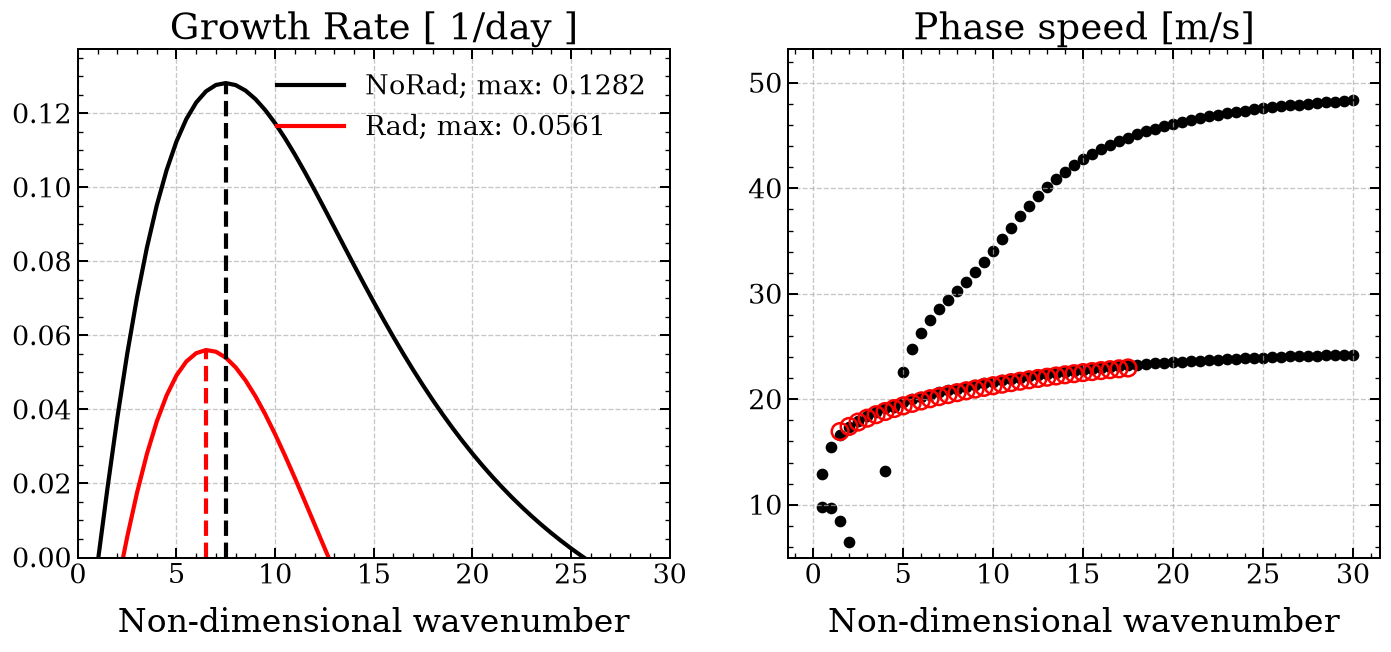

In [54]:
fig, axes = plt.subplots(1, 2)

ax1, ax2 = axes.flatten()

ax1.plot(nondim_k["NoRad"], dominant_growth_rate["NoRad"], color="k", label=f"NoRad; max: {np.round(np.max(dominant_growth_rate['NoRad']), decimals=4)}")
ax1.plot(nondim_k["Rad"], dominant_growth_rate["Rad"], color="r", label=f"Rad; max: {np.round(np.max(dominant_growth_rate['Rad']), decimals=4)}")
ax1.vlines(
    nondim_k["NoRad"][np.argmax(dominant_growth_rate["NoRad"])],
    0, np.max(dominant_growth_rate["NoRad"]),
    color="k", linestyle="--")
ax1.vlines(
    nondim_k["Rad"][np.argmax(dominant_growth_rate["Rad"])],
    0, np.max(dominant_growth_rate["Rad"]),
    color="r", linestyle="--")
ax1.set_xlim(0, 30)
ax1.set_ylim(0, None)
ax1.set_xlabel("Non-dimensional wavenumber")
ax1.set_title("Growth Rate [ 1/day ]")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.7)

for i in range(6):
    ax2.scatter(nondim_k["NoRad"], phase_speed["NoRad"][i, :], color="k", label="NoRad")
    # Draw non-dominant Rad points in red; dominant points are drawn below.
    non_dominant = dominant_mode["Rad"] != i
    # ax2.scatter(nondim_k["Rad"][non_dominant], phase_speed["Rad"][i, non_dominant], color="r", label="Rad")

ax2.scatter(
    nondim_k["Rad"], dominant_phase_speed["Rad"],
    marker="o", s=100, facecolors="none", edgecolors="red",
    linewidths=1.5, zorder=3, label="Rad dominant",
)
ax2.set_ylim(5, None)
ax2.set_xlabel("Non-dimensional wavenumber")
ax2.set_title("Phase speed [m/s]")
ax2.grid(True, linestyle="--", alpha=0.7)

plt.savefig("/home/b11209013/Kuang-python/Analysis/Figure/eigen_analysis.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()